# Step 5 — Critical Thinking: Ethical AI & Bias Auditing
### Capstone: Detecting Fraudulent Transactions

This notebook computes the evidence for the **Bias & Fairness Analysis** section of your final
report: model explanations (SHAP, PDP, ICE), limitation checks, and fairness metrics.

> **Honest constraint — read first.** `creditcard.csv` contains **no sensitive attributes**
> (no gender, race, age, or socioeconomic status). The only interpretable raw feature is
> `Amount`. So a direct protected-group audit is **impossible on this data** — and that is
> itself an ethical finding worth stating plainly. To still demonstrate the methodology, we
> use **transaction `Amount` as a declared socioeconomic *proxy*** (higher value loosely
> tracks spending power). Treat every proxy result as illustrative of method, not as proof
> the model is fair to real demographic groups.


In [1]:
import os, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import (average_precision_score, precision_recall_curve)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Ready.")

Ready.


In [2]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


## 1. Rebuild data + champion model
We keep an **unscaled copy of `Amount`** for grouping. We train a Random Forest champion here
to stay self-contained; to use your Step 4 artifact instead, `joblib.load("models/RandomForest.joblib")`
and `joblib.load("models/scaler.joblib")`.

In [3]:
df = pd.read_csv("creditcard.csv").drop_duplicates().reset_index(drop=True)
df["Hour"] = (df["Time"] // 3600) % 24
df["Log_Amount"] = np.log1p(df["Amount"])
df["Amount_bin"] = pd.qcut(df["Amount"], q=5, labels=False, duplicates="drop")

amount_raw = df["Amount"].copy()          # unscaled, for fairness grouping
X = df.drop(columns=["Class"]); y = df["Class"]

X_tr, X_te, y_tr, y_te, amt_tr, amt_te = train_test_split(
    X, y, amount_raw, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

to_scale = ["Time", "Amount", "Log_Amount", "Hour"]
scaler = RobustScaler()
X_tr[to_scale] = scaler.fit_transform(X_tr[to_scale])
X_te[to_scale] = scaler.transform(X_te[to_scale])

model = RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1,
                               class_weight="balanced", random_state=RANDOM_STATE)
model.fit(X_tr, y_tr)
print("Champion trained.")

Champion trained.


### Operating threshold
Tuned for F2 on **training** cross-validation probabilities (no test leakage), reused from
Step 4's logic.

In [4]:
def best_threshold(y_true, s, beta=2.0):
    p, r, thr = precision_recall_curve(y_true, s); p, r = p[:-1], r[:-1]
    fb = (1+beta**2)*p*r / (beta**2*p + r + 1e-12)
    return float(thr[int(np.nanargmax(fb))])

skf = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(model, X_tr, y_tr, cv=skf, method="predict_proba", n_jobs=-1)[:,1]
THRESHOLD = best_threshold(y_tr, oof)

test_scores = model.predict_proba(X_te)[:,1]
y_pred = (test_scores >= THRESHOLD).astype(int)
print("Operating threshold:", round(THRESHOLD, 4))
print("Test AUC-PR:", round(average_precision_score(y_te, test_scores), 4))

Operating threshold: 0.2518
Test AUC-PR: 0.7928


## 2. Explaining model decisions

### 2.1 SHAP — global + per-feature contributions
SHAP is the backbone of your explainability story: which
features push a transaction toward "fraud", and by how much.

C:\Users\johan\AppData\Local\Temp\ipykernel_24096\2368311030.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, sample, show=True)


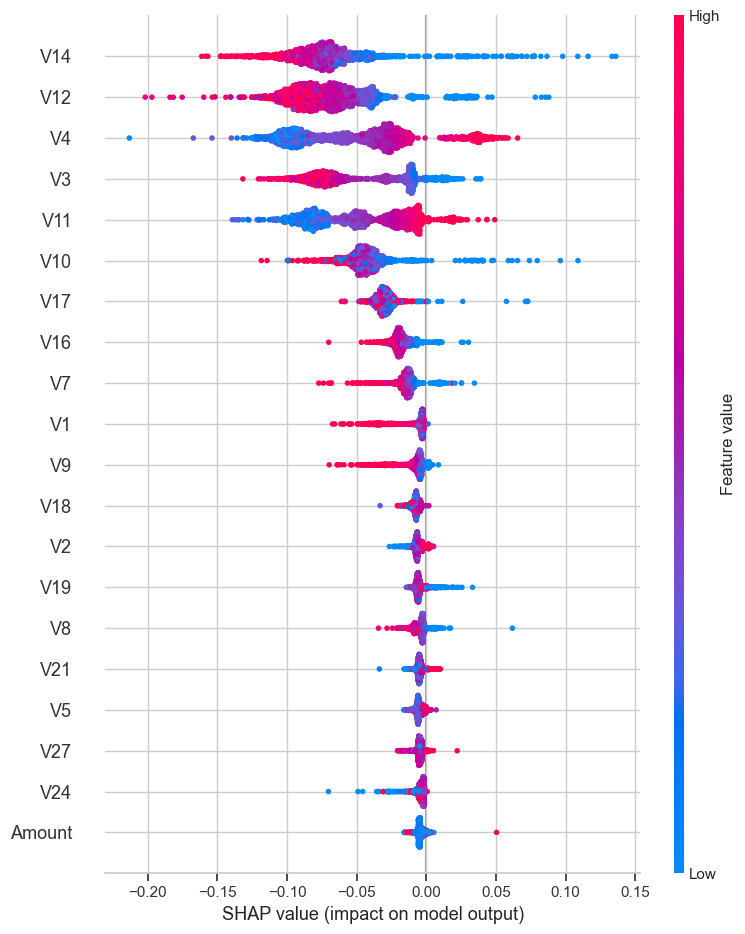

In [5]:
try:
    import shap
    sample = X_tr.sample(2000, random_state=RANDOM_STATE)
    sv = shap.TreeExplainer(model).shap_values(sample)
    if isinstance(sv, list):            # older shap: [class0, class1]
        sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3:   # newer shap: (rows, features, classes)
        sv = sv[:, :, 1]
    shap.summary_plot(sv, sample, show=True)
except ImportError:
    print("shap not installed -> pip install shap")

### 2.2 Partial Dependence (PDP) — average effect of a feature
PDP shows how the predicted fraud probability changes as one feature varies, averaged over
everyone. We plot it for the most important features.

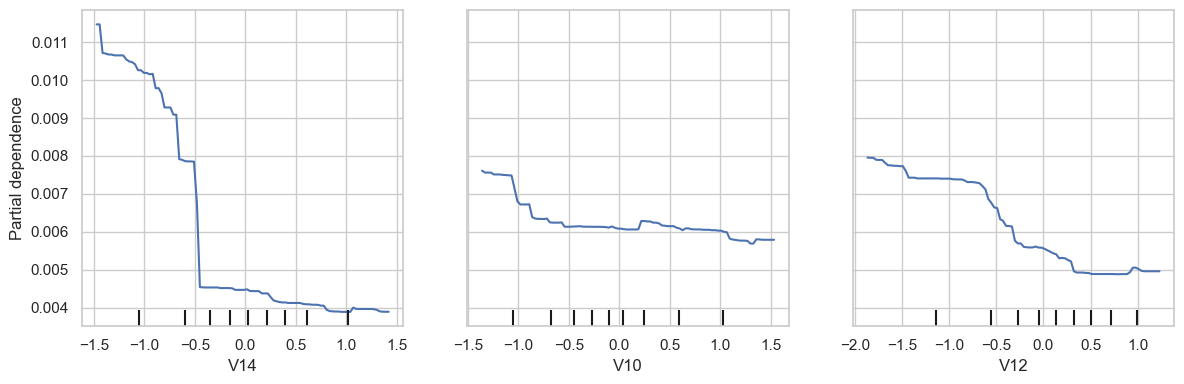

PDP features: ['V14', 'V10', 'V12']


In [6]:
top = (pd.Series(model.feature_importances_, index=X_tr.columns)
       .sort_values(ascending=False).head(3).index.tolist())
fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(model, X_tr.sample(5000, random_state=RANDOM_STATE),
                                        features=top, ax=ax, kind="average")
plt.tight_layout(); plt.show()
print("PDP features:", top)

### 2.3 ICE — individual effect per transaction
ICE draws one line per transaction (PDP is their average). Diverging lines reveal that a
feature affects different transactions differently — important for spotting heterogeneous
behaviour. Shown on a small sample for legibility.

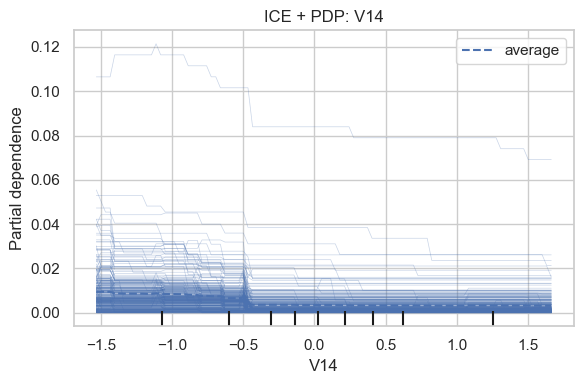

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
PartialDependenceDisplay.from_estimator(model, X_tr.sample(300, random_state=RANDOM_STATE),
                                        features=[top[0]], ax=ax, kind="both")
plt.title(f"ICE + PDP: {top[0]}"); plt.tight_layout(); plt.show()

### 2.4 LIME (optional) — local explanation of one prediction
`pip install lime`. LIME explains a *single* transaction by fitting a simple local model.
Useful for "why was THIS transaction flagged?" in an investigation workflow.

In [8]:
try:
    from lime.lime_tabular import LimeTabularExplainer
    expl = LimeTabularExplainer(X_tr.values, feature_names=list(X_tr.columns),
                                class_names=["legit","fraud"], discretize_continuous=True)
    i = y_te.reset_index(drop=True)[y_te.reset_index(drop=True)==1].index[0]  # a fraud case
    exp = expl.explain_instance(X_te.iloc[i].values, model.predict_proba, num_features=8)
    print("Local explanation for a fraud transaction:")
    for feat, w in exp.as_list():
        print(f"  {feat:40s} {w:+.4f}")
except ImportError:
    print("lime not installed -> pip install lime")

Local explanation for a fraud transaction:
  V14 <= -0.43                             +0.0098
  V4 > 0.74                                +0.0088
  V12 <= -0.40                             +0.0074
  V11 > 0.74                               +0.0050
  V10 <= -0.54                             +0.0044
  V3 <= -0.89                              +0.0033
  V19 > 0.46                               +0.0028
  V17 <= -0.48                             +0.0027


C:\Users\johan\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## 3. Fairness audit on a declared proxy

### 3.1 The sensitive-attribute problem (state this in the report)
There are no demographic columns, so we cannot audit gender/race/age. We declare a
**socioeconomic proxy**: high- vs low-value transactions split at the median `Amount`.
Interpret results as a *method demonstration*, not a demographic guarantee.

In [9]:
med = amt_te.median()
group = np.where(amt_te.values > med, "high_value", "low_value")
print("Median Amount split:", round(med, 2))
print(pd.Series(group).value_counts())

Median Amount split: 21.59
low_value     28373
high_value    28373
Name: count, dtype: int64


### 3.2 Fairness metrics across groups
- **Demographic (statistical) parity** — do groups get flagged at similar rates?
- **Disparate impact ratio** — min/max flag rate; **< 0.80 is the classic red flag** (the
  group flagged far more experiences more friction — here being flagged is the *adverse*
  outcome for the customer).
- **Equalised odds / equal opportunity** — are true-positive and false-positive rates equal
  across groups?

In [10]:
def group_metrics(y_true, y_pred, groups):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    rows = []
    for g in np.unique(groups):
        m = groups == g
        yt, yp = y_true[m], y_pred[m]
        tp = int(((yp==1)&(yt==1)).sum()); fn = int(((yp==0)&(yt==1)).sum())
        fp = int(((yp==1)&(yt==0)).sum()); tn = int(((yp==0)&(yt==0)).sum())
        rows.append({"group": g, "n": int(m.sum()),
                     "flag_rate": yp.mean(),
                     "TPR_recall": tp/(tp+fn) if tp+fn else np.nan,
                     "FPR": fp/(fp+tn) if fp+tn else np.nan})
    return pd.DataFrame(rows)

fair = group_metrics(y_te.values, y_pred, group)
display(fair)

di = fair["flag_rate"].min() / fair["flag_rate"].max()
print(f"Disparate impact ratio (flag rate): {di:.3f}  "
      f"({'PASS' if di >= 0.8 else 'FLAG'} vs 0.80 rule)")
print(f"Equal-opportunity gap |ΔTPR|: {abs(fair['TPR_recall'].diff().iloc[-1]):.3f}")
print(f"Equalised-odds gap   |ΔFPR|: {abs(fair['FPR'].diff().iloc[-1]):.3f}")

,group,n,flag_rate,TPR_recall,FPR
0,high_value,28373,0.0018,0.8222,0.0005
1,low_value,28373,0.0016,0.7600,0.0002


Disparate impact ratio (flag rate): 0.863  (PASS vs 0.80 rule)
Equal-opportunity gap |ΔTPR|: 0.062
Equalised-odds gap   |ΔFPR|: 0.000


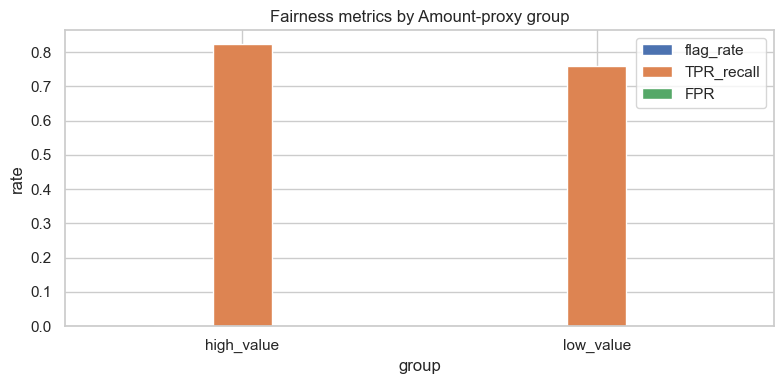

In [11]:
fair.set_index("group")[["flag_rate","TPR_recall","FPR"]].plot(
    kind="bar", figsize=(8,4))
plt.title("Fairness metrics by Amount-proxy group"); plt.ylabel("rate")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 4. Limitations — checked, not just listed

### 4.1 Overfitting: train vs test gap
A large gap (train far above test) signals overfitting.

In [12]:
train_ap = average_precision_score(y_tr, model.predict_proba(X_tr)[:,1])
test_ap  = average_precision_score(y_te, test_scores)
print(f"Train AUC-PR: {train_ap:.4f} | Test AUC-PR: {test_ap:.4f} | gap: {train_ap-test_ap:.4f}")

Train AUC-PR: 0.9799 | Test AUC-PR: 0.7928 | gap: 0.1871


### 4.2 Imbalance & leakage (narrative)
- **Imbalance** (~0.17% fraud) handled with `class_weight` + threshold tuning; accuracy avoided.
- **Leakage** prevented by splitting before scaling, fitting transforms on train only, and
  tuning the threshold on train CV. Any SMOTE stays inside CV folds.
These are design safeguards; cite them in the report as mitigations already in place.